# Etapa III — Comparación, selección e interpretación de modelos
**Problema:** pronosticar las subidas registradas de buses por sector (Oriente, Sur), tipo de día y franja de 30 minutos, y etiquetar la intensidad horaria (Nulo/Bajo/Medio/Alto).

> Nota de alcance: se pronostican *subidas registradas* (validaciones), no pasajeros reales corregidos por evasión, como se planteó en la Etapa I.

**Framework:** CRISP-DM. Este notebook cubre *Modeling* y *Evaluation* y reproduce todas las cifras de la presentación.

## 1. Mejoras respecto a la Etapa II
- Base auditada y reproducible (Hito 1): panel con hashes SHA-256, distinción entre ausencia y cero, y controles de fuga temporal.
- Antes solo había dos baselines; ahora se comparan **4 métodos**: dos baselines y dos modelos de ML.
- Validación temporal de **origen móvil**, en lugar de evaluar un único corte.
- Métricas nuevas: sesgo (error firmado), WAPE por tipo de día y subestimación en franjas *Alto*.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'Etapa_03/codigo'))
pd.set_option('display.precision', 2)

## 2. Base reproducible (Hito 1)
Regenera el perfil sectorial y las predicciones de los baselines, y verifica que coincidan con la Etapa II.

In [2]:
import base_reproducible
base_reproducible.main()

periodo  sector  n_total  n_evaluadas  n_incompletas  n_sin_historial  pct_evaluadas  pct_incompletas  pct_sin_historial
2025-04 Oriente      144          131             10                3          90.97             6.94               2.08
2025-04     Sur      144          119             23                2          82.64            15.97               1.39
2025-11 Oriente      144          134              7                3          93.06             4.86               2.08
2025-11     Sur      144          119             24                1          82.64            16.67               0.69
2026-04 Oriente      144          135              8                1          93.75             5.56               0.69
2026-04     Sur      144          117             27                0          81.25            18.75               0.00
periodo  sector           metodo   n    MAE  WAPE_pct  acierto_etiqueta_pct  altos_reales  altos_detectados
2026-04 Oriente  Media histórica 135 618.23  

## 3. Modelos y validación (Hito 2)
| Método | Descripción |
|---|---|
| Media histórica | Promedio de los cortes completos anteriores para la misma franja |
| Último observado | Valor del corte completo más reciente |
| Ridge (log) | Regresión lineal regularizada que corrige la media histórica en escala logarítmica |
| Gradient Boosting (log) | Árboles con boosting sobre las mismas variables |

**Variables:** log de la media histórica, log del último observado, hora (seno/coseno), tipo de día, sector y temporada (noviembre vs abril).

**Validación de origen móvil (sin fuga):** para probar en 2025-11 se entrena con 2025-04; para probar en 2026-04 se entrena con 2025-04 y 2025-11. No usamos K-fold aleatorio porque mezclaría el futuro con el pasado.

**Métrica principal:** WAPE, que es el error absoluto total dividido por las subidas totales. Es interpretable en % y pondera más las franjas con más pasajeros.

In [3]:
import comparacion_modelos
comparacion_modelos.main()

                 metodo     n    MAE  WAPE_pct  sesgo_pct  acierto_etiqueta_pct  altos_reales  altos_detectados  subestimacion_altos_pct
        Media histórica 505.0 472.01      6.95      -1.84                 90.69         166.0             159.0                     4.45
            Ridge (log) 505.0 478.65      7.05      -3.18                 92.87         166.0             151.0                     5.03
Gradient Boosting (log) 505.0 531.51      7.83      -0.67                 87.52         166.0             151.0                     3.81
       Último observado 505.0 622.79      9.18      -1.48                 84.95         166.0             144.0                     5.06

WAPE por corte:
 periodo                  2025-11  2026-04
metodo                                   
Gradient Boosting (log)    11.00     4.70
Media histórica             5.60     8.29
Ridge (log)                 6.43     7.67
Último observado            8.78     9.57

Seleccionado: Media histórica | gana en ambo

In [4]:
R = ROOT / 'Etapa_03/resultados/hito_2'
pd.read_csv(R / 'metricas_conjuntas.csv')

,metodo,n,MAE,WAPE_pct,sesgo_pct,acierto_etiqueta_pct,altos_reales,altos_detectados,subestimacion_altos_pct
0,Media histórica,505.0,472.01,6.95,-1.84,90.69,166.0,159.0,4.45
1,Ridge (log),505.0,478.65,7.05,-3.18,92.87,166.0,151.0,5.03
2,Gradient Boosting (log),505.0,531.51,7.83,-0.67,87.52,166.0,151.0,3.81
3,Último observado,505.0,622.79,9.18,-1.48,84.95,166.0,144.0,5.06


## 4. Comparación visual

Figuras en C:\Users\Cristobal C\Desktop\demanda-bus-santiago-main\Etapa_03\resultados\figuras


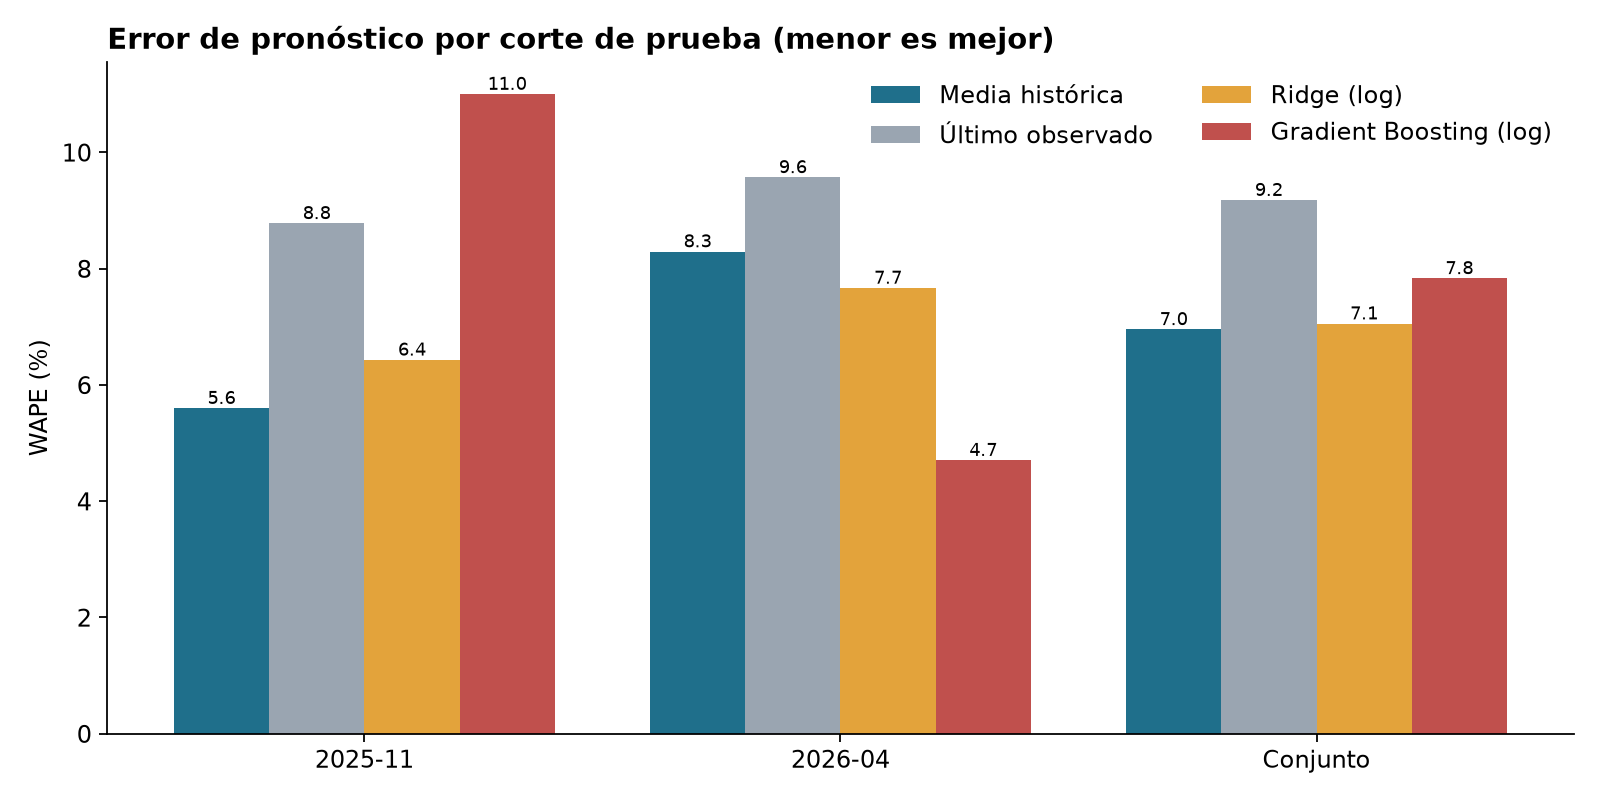

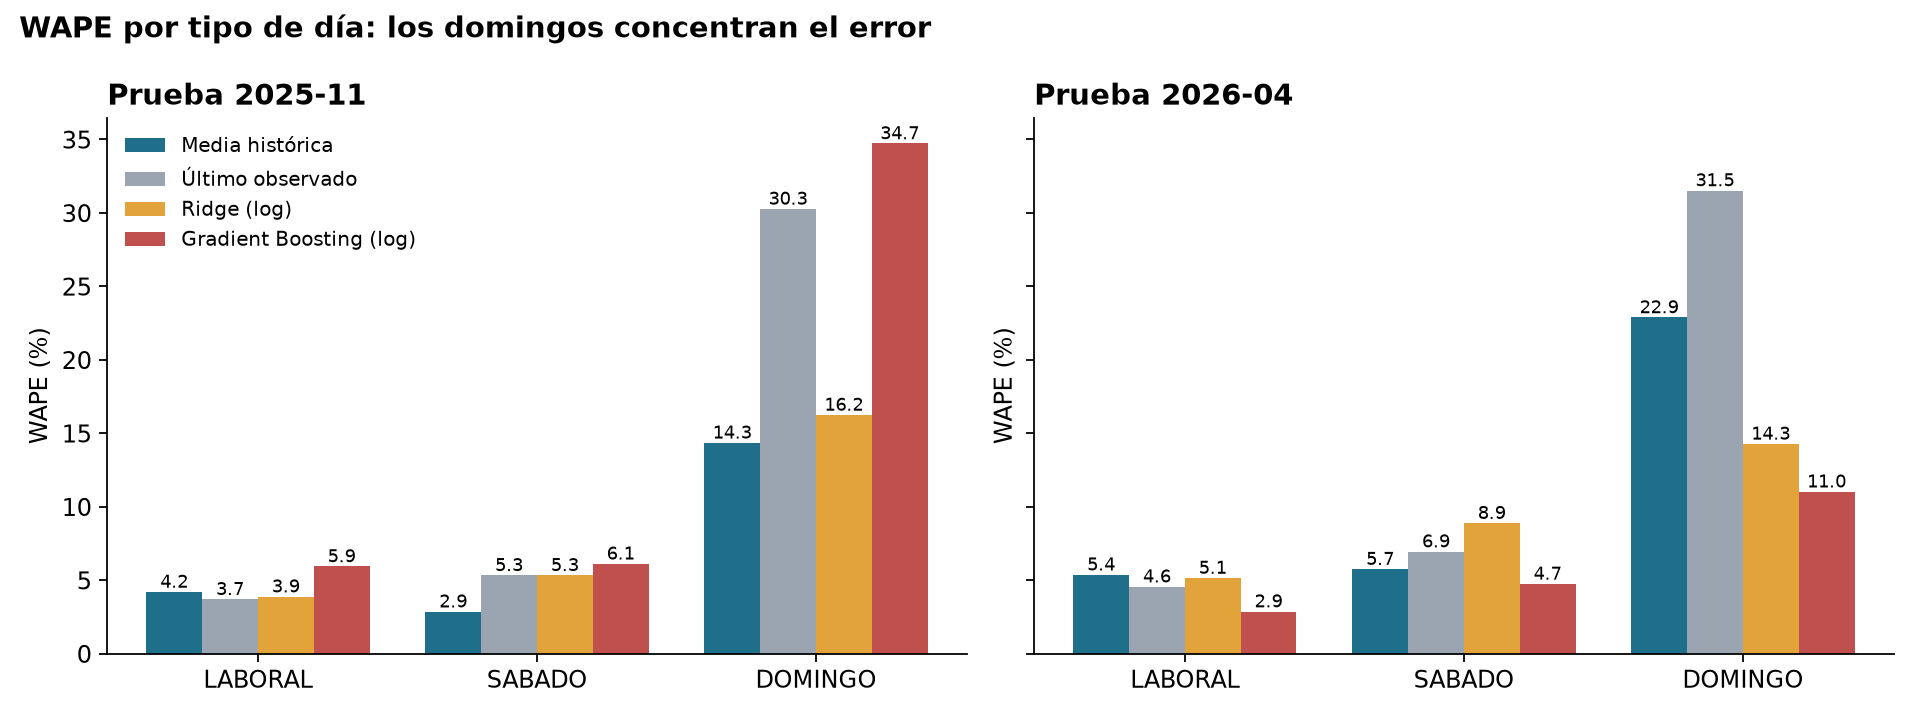

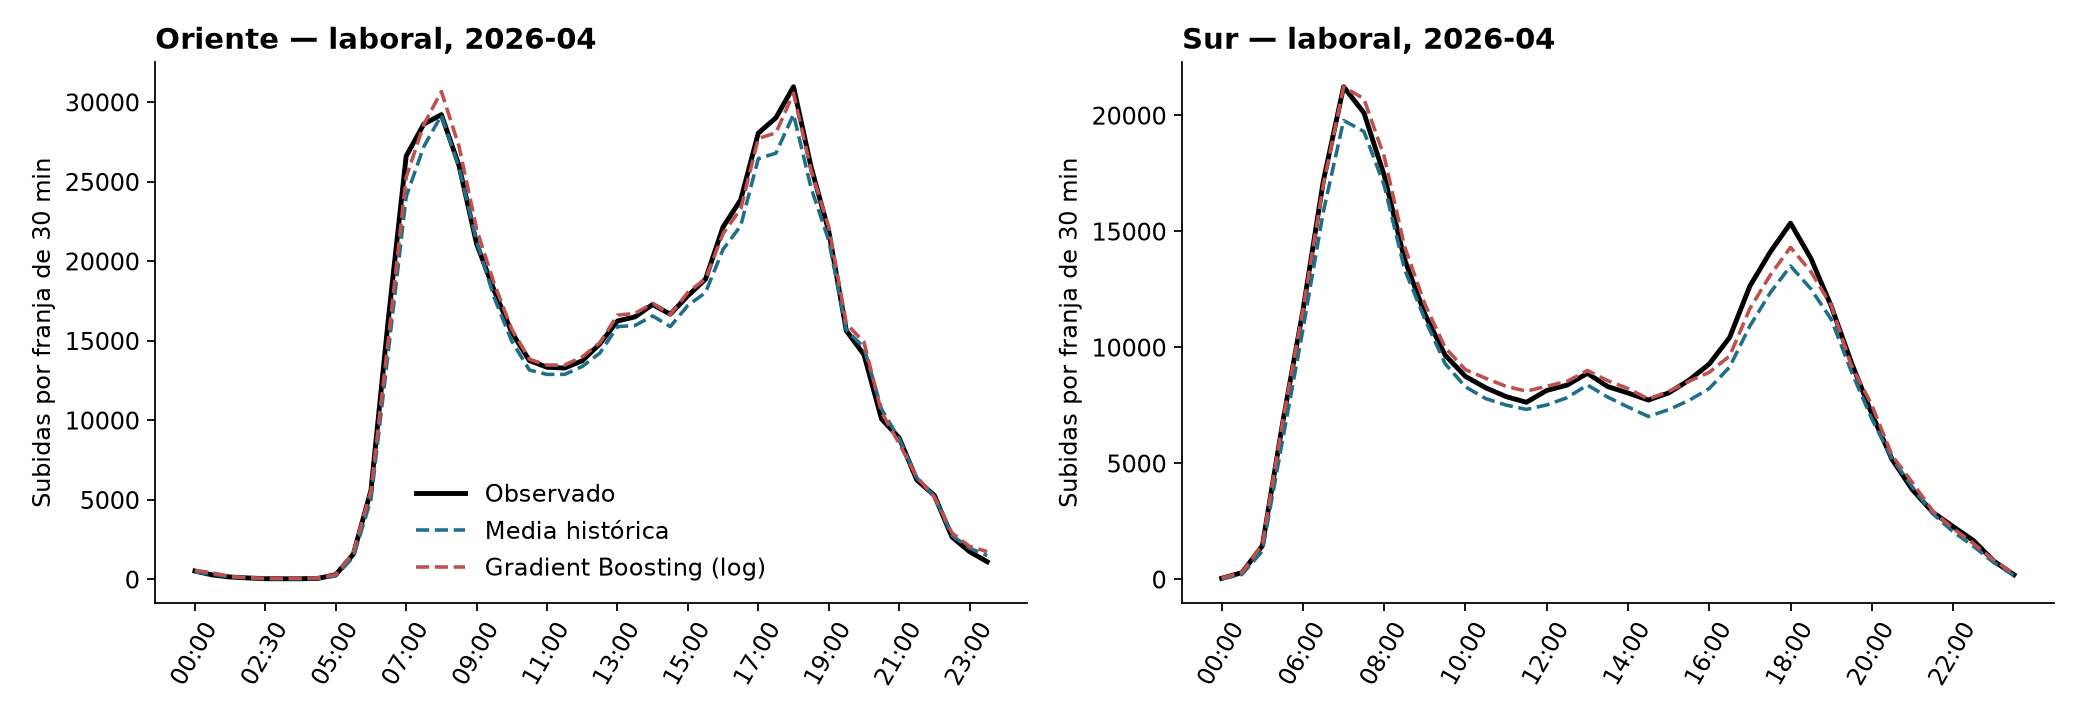

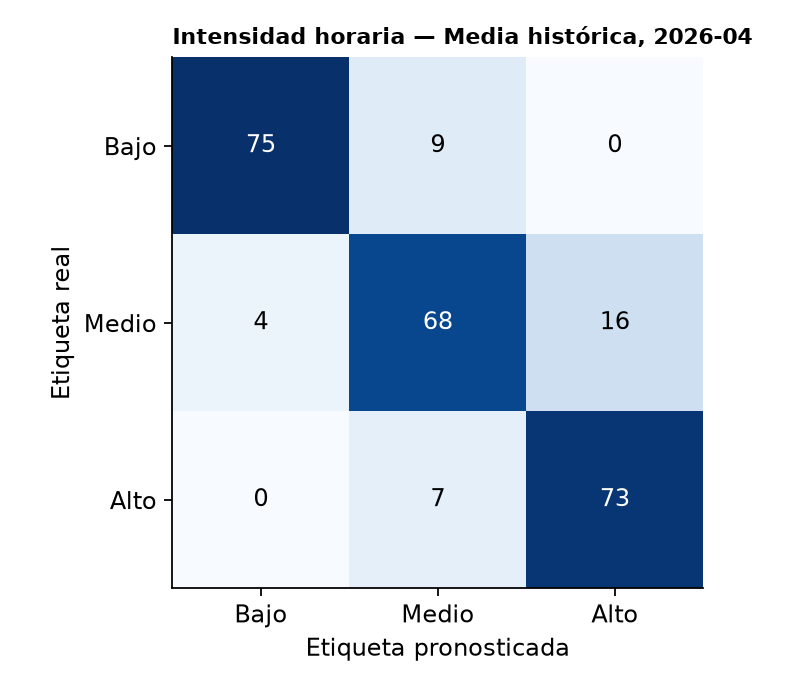

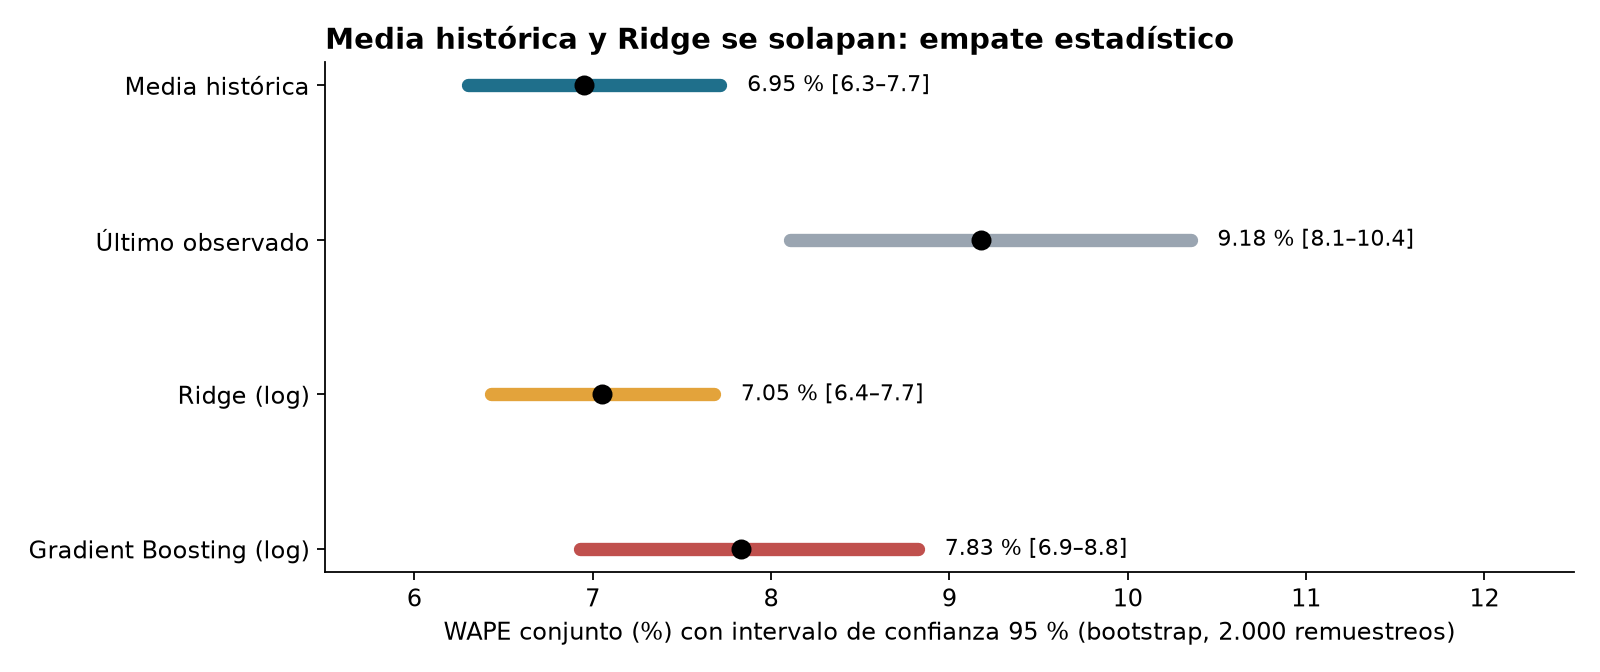

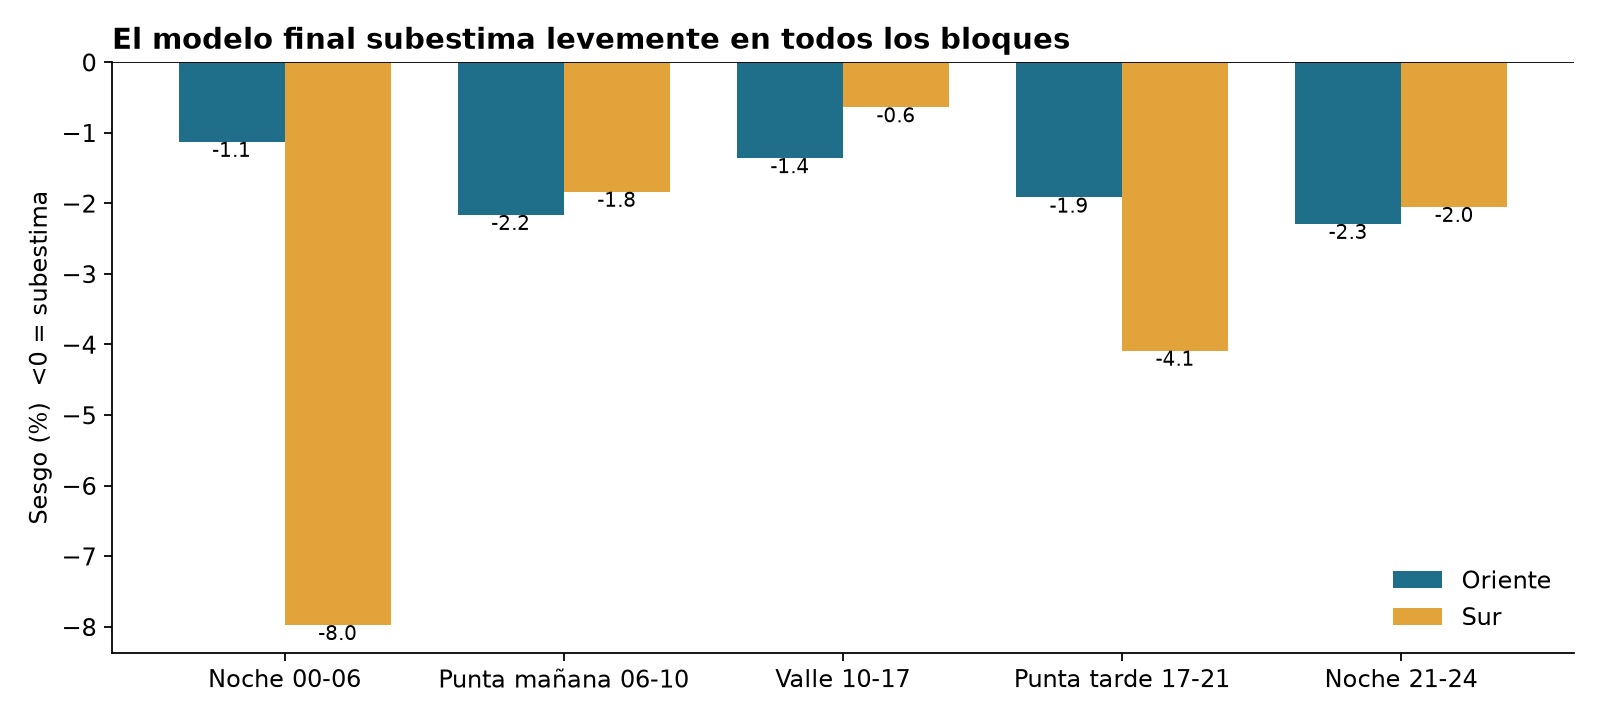

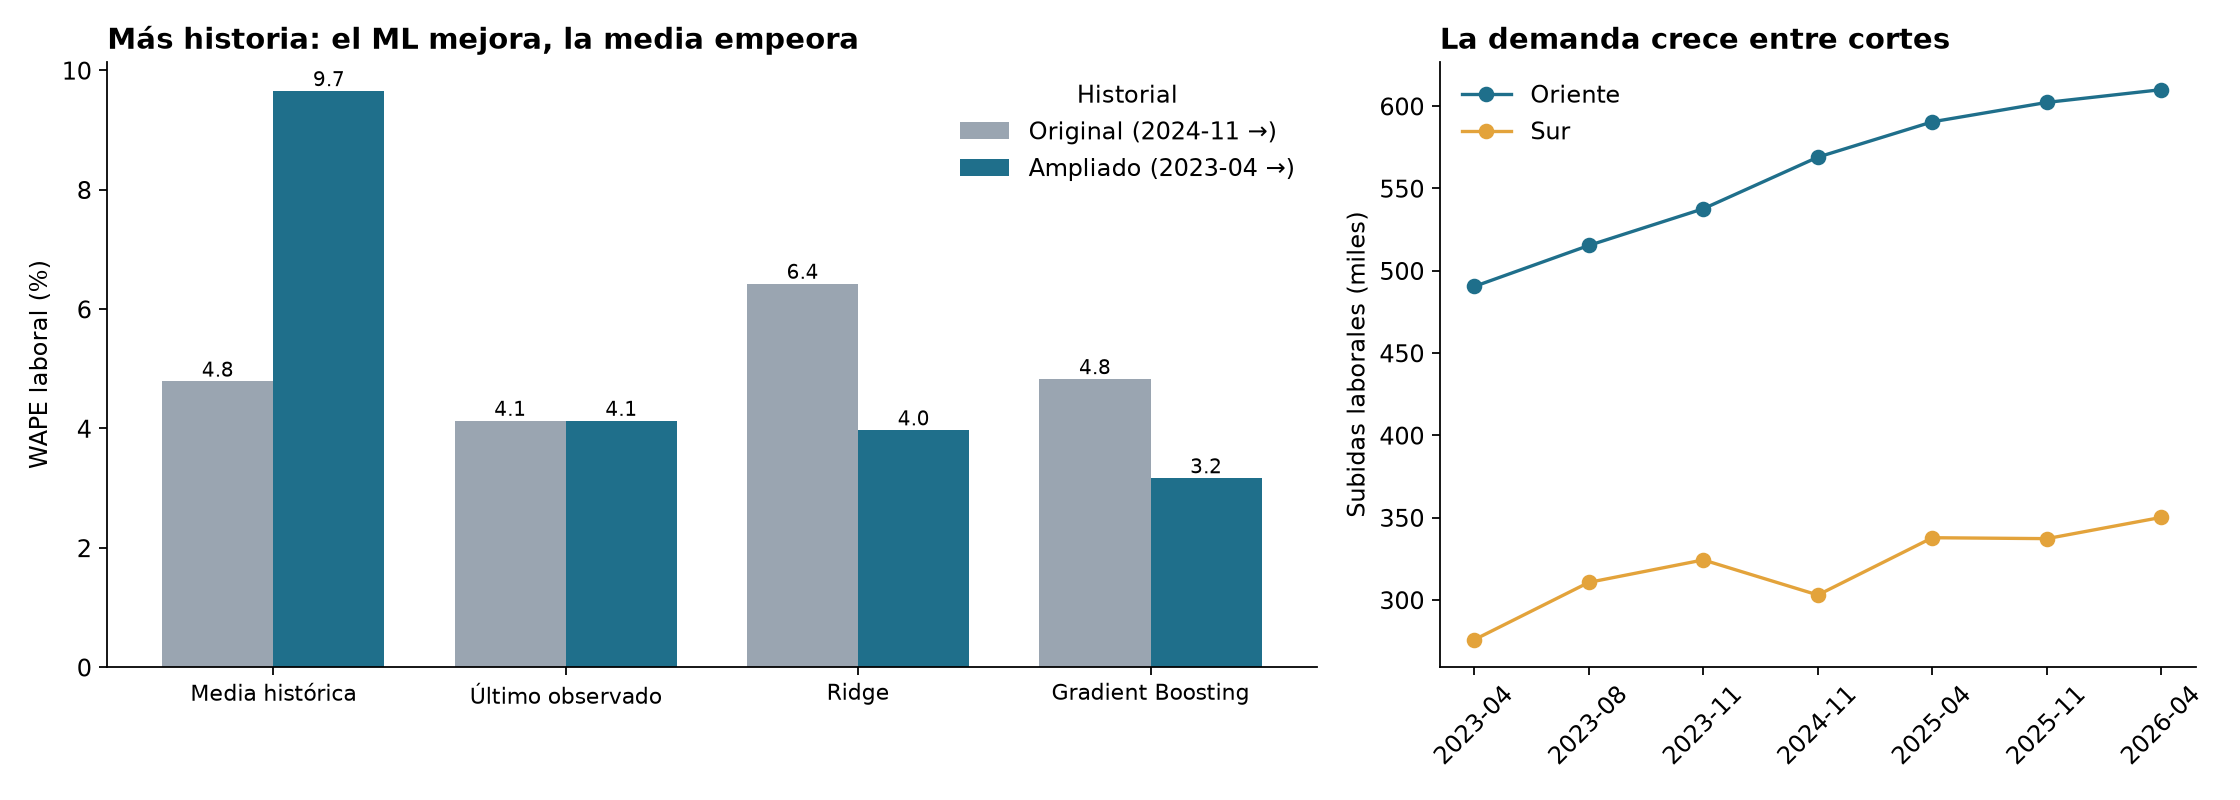

In [5]:
import figuras_hito_3
figuras_hito_3.main()
F = ROOT / 'Etapa_03/resultados/figuras'
for f in sorted(F.glob('*.png')):
    display(Image(filename=str(f)))

In [6]:
d = pd.read_csv(R / 'metricas_por_tipo_dia.csv')
d.pivot_table(index='metodo', columns=['periodo', 'tipo_dia'], values='WAPE_pct')

periodo                 2025-11                2026-04               
tipo_dia                DOMINGO LABORAL SABADO DOMINGO LABORAL SABADO
metodo                                                               
Gradient Boosting (log)   34.72    5.93   6.11   11.02    2.86   4.74
Media histórica           14.35    4.19   2.85   22.88    5.37   5.75
Ridge (log)               16.24    3.88   5.33   14.27    5.14   8.87
Último observado          30.27    3.70   5.33   31.52    4.56   6.94

## 4b. Robustez de la validación
1. **Bootstrap** (2.000 remuestreos de franjas dentro de cada corte): intervalo de confianza 95 % del WAPE y de la diferencia de cada método contra la media histórica.
2. **RMSE**: penaliza más los errores grandes de las horas punta.
3. **Ajuste de hiperparámetros sin fuga**: grilla entrenada con 2025-04 y validada con 2025-11. La mejor configuración se reentrena con ambos cortes y se prueba **una sola vez** en 2026-04.
4. **Importancia por permutación** en 2026-04 y **residuos** del modelo final por sector y bloque horario.

In [7]:
import validacion_robustez
validacion_robustez.main()

factor_umbral             0.8   0.9   1.0   1.1   1.2
metodo                                               
Gradient Boosting (log)  91.9  88.1  87.5  89.1  92.3
Media histórica          93.1  92.1  90.7  90.7  92.5
Ridge (log)              95.0  93.3  92.9  92.5  93.1
Último observado         91.7  87.3  85.0  86.3  88.9
factor_umbral             0.8   0.9   1.0   1.1   1.2
metodo                                               
Gradient Boosting (log)  92.3  89.2  91.0  89.3  91.3
Media histórica          92.8  95.7  95.8  95.6  90.6
Ridge (log)              97.7  96.2  91.0  88.7  88.6
Último observado         94.1  88.2  86.7  89.3  89.3


                 metodo  WAPE_pct  IC95_inf  IC95_sup  dif_vs_media  dif_IC95_inf  dif_IC95_sup  prob_mejor_que_media   RMSE
        Media histórica      6.95      6.30      7.72          0.00          0.00          0.00                   NaN 698.69
            Ridge (log)      7.05      6.43      7.68          0.09         -0.56          0.73                  0.40 698.02
Gradient Boosting (log)      7.83      6.93      8.82          0.87          0.11          1.68                  0.01 882.97
       Último observado      9.18      8.10     10.35          2.23          1.61          2.88                  0.00 990.52

  sector             bloque  n  error_medio  sesgo_pct  WAPE_pct
Oriente        Noche 00-06 53         -3.9       -1.1      13.2
Oriente Punta mañana 06-10 48       -227.5       -2.2       4.1
Oriente        Valle 10-17 84       -147.7       -1.4       7.5
Oriente  Punta tarde 17-21 48       -231.7       -1.9       7.5
Oriente        Noche 21-24 36        -77.3       -2.3

In [8]:
R2 = ROOT / 'Etapa_03/resultados/hito_2b'
pd.read_csv(R2 / 'bootstrap_wape.csv')

,metodo,WAPE_pct,IC95_inf,IC95_sup,dif_vs_media,dif_IC95_inf,dif_IC95_sup,prob_mejor_que_media,RMSE
0,Media histórica,6.95,6.30,7.72,0.00,0.00,0.00,NaN,698.69
1,Ridge (log),7.05,6.43,7.68,0.09,-0.56,0.73,0.40,698.02
2,Gradient Boosting (log),7.83,6.93,8.82,0.87,0.11,1.68,0.01,882.97
3,Último observado,9.18,8.10,10.35,2.23,1.61,2.88,0.00,990.52


**Lectura:** la diferencia entre Ridge y la media histórica es de +0,09 pp, con IC 95 % de [−0,56; +0,73]. Incluye el 0, así que es un **empate estadístico**. Gradient Boosting (+0,87 pp, IC [0,11; 1,68]) y Último observado (+2,23 pp) son **significativamente peores** en el conjunto.

In [9]:
display(pd.read_csv(R2 / 'ajuste_hiperparametros_resumen.csv'))
pd.read_csv(R2 / 'importancia_variables.csv').sort_values(['metodo', 'importancia'], ascending=[True, False])

,metodo,mejores_params,WAPE_prueba_2026_04
0,Ridge (log),{'alpha': 10},8.45
1,Gradient Boosting (log),"{'max_depth': 2, 'learning_rate': 0.03, 'max_i...",6.01
2,Media histórica,{},8.29


,metodo,variable,importancia,desv
16,Gradient Boosting (log),dia_DOMINGO,4.27e-02,4.41e-03
10,Gradient Boosting (log),log_ultimo,3.80e-02,4.61e-03
14,Gradient Boosting (log),dia_LABORAL,8.09e-03,2.97e-03
9,Gradient Boosting (log),log_media,7.74e-03,1.92e-03
12,Gradient Boosting (log),hora_cos,9.70e-04,5.08e-04
15,Gradient Boosting (log),dia_SABADO,4.04e-04,2.61e-04
17,Gradient Boosting (log),sector_sur,2.69e-04,2.73e-04
11,Gradient Boosting (log),hora_sin,0.00e+00,0.00e+00
13,Gradient Boosting (log),temporada_nov,0.00e+00,0.00e+00
1,Ridge (log),log_ultimo,9.41e-02,6.45e-03


**Lectura:** con un ajuste de hiperparámetros honesto, Gradient Boosting queda en **6,0 %** en 2026-04, contra 8,3 % de la media histórica. El 4,7 % sin ajustar era en parte suerte de la configuración. La señal de que el ML mejora con más historia se mantiene, pero solo hay un corte que lo confirme.

Las variables que más pesan son el **último observado** y el **tipo de día (domingo)**: el ML corrige la media histórica según la tendencia reciente y la variabilidad del domingo. *Temporada* aparece con importancia 0 porque es constante dentro del corte de prueba, no porque no sirva.

In [10]:
pd.read_csv(R2 / 'residuos_modelo_final.csv')

,sector,bloque,n,error_medio,sesgo_pct,WAPE_pct
0,Oriente,Noche 00-06,53,-3.88,-1.13,13.24
1,Oriente,Punta mañana 06-10,48,-227.49,-2.16,4.05
2,Oriente,Valle 10-17,84,-147.71,-1.36,7.51
3,Oriente,Punta tarde 17-21,48,-231.72,-1.92,7.53
4,Oriente,Noche 21-24,36,-77.35,-2.29,8.05
5,Sur,Noche 00-06,20,-86.97,-7.97,9.51
6,Sur,Punta mañana 06-10,48,-145.09,-1.83,4.96
7,Sur,Valle 10-17,84,-40.35,-0.64,7.80
8,Sur,Punta tarde 17-21,48,-256.92,-4.09,8.53
9,Sur,Noche 21-24,36,-30.19,-2.05,9.74


**Lectura de residuos:** el modelo final **subestima en todos los bloques** (≈ −1 % a −4 %), con el mayor sesgo en la punta de la tarde del Sur (−4,1 %) y en la madrugada del Sur (−8 %, con poco volumen). La demanda creció entre cortes y la media histórica reacciona con rezago.

## 4c. Historial ampliado con las Subidas laborales de 2023
Se agregan las Subidas de abril, agosto y noviembre de 2023. Esos libros **solo traen días laborales** y **no tienen columna de modo**, así que el filtro BUS es por paradero y código de servicio T/F/B, excluyendo las líneas de Metro y Metrotren. Una comuna sin valor en una franja queda como ausente, no como cero.

Se comparan las **mismas 172 franjas laborales** de las pruebas 2025-11 y 2026-04 con el historial original y con el ampliado. Gradient Boosting usa los hiperparámetros ajustados en 4b.

In [11]:
import ampliacion_2023
ampliacion_2023.main()

Filas BUS 2023: [65049, 65749, 66920]
periodo  sector  franjas_completas_de_48
2023-04 Oriente                       46
2023-04     Sur                       40
2023-08 Oriente                       45
2023-08     Sur                       40
2023-11 Oriente                       44
2023-11     Sur                       42

Volumen laboral sumado (franjas completas):
 sector    Oriente       Sur
periodo                    
2023-04  490442.0  275808.0
2023-08  515346.0  310638.0
2023-11  537653.0  324295.0
2024-11  568993.0  302975.0
2025-04  590469.0  337778.0
2025-11  602257.0  337214.0
2026-04  610012.0  350158.0

            historial                  metodo     n  WAPE_pct  sesgo_pct  n_entreno_ultimo_corte  WAPE_IC95_inf  WAPE_IC95_sup  dif_vs_seleccionado  dif_IC95_inf  dif_IC95_sup
Ampliado (2023-04 →) Gradient Boosting (log) 172.0      3.17      -1.79                   429.0           2.74           3.62                -1.63         -2.05         -1.20
Ampliado (2023-04 →)     

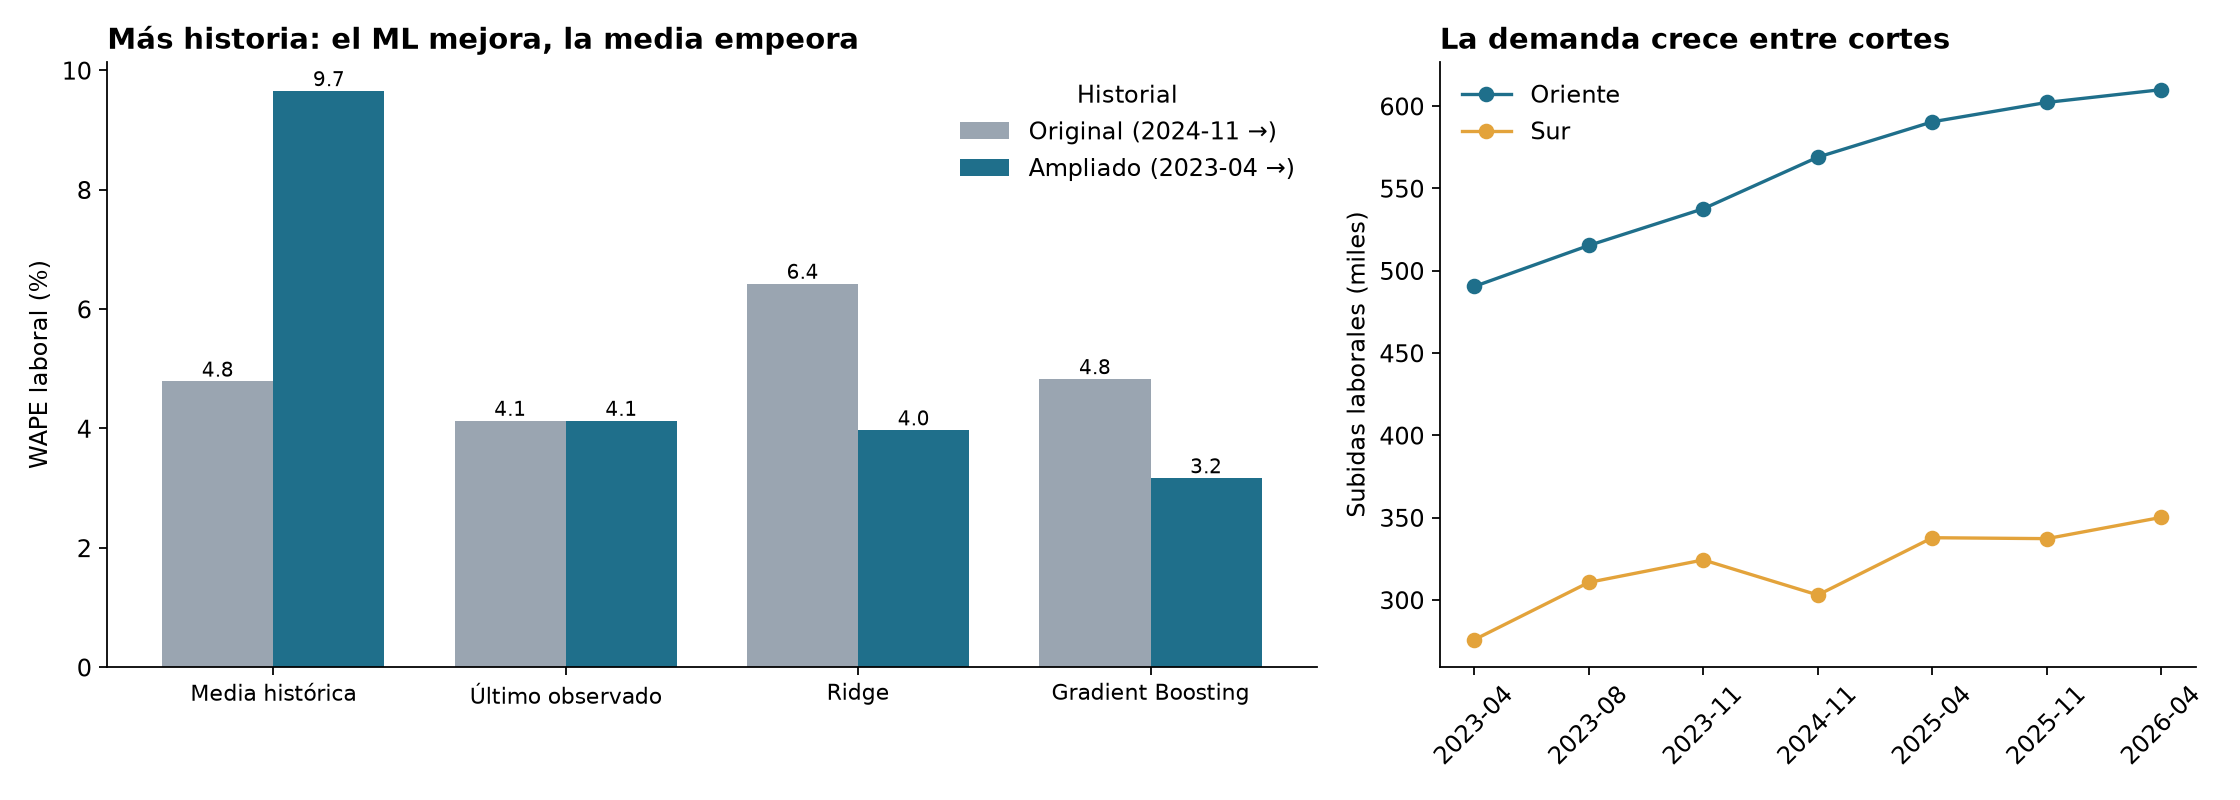

,historial,metodo,n,WAPE_pct,sesgo_pct,n_entreno_ultimo_corte,WAPE_IC95_inf,WAPE_IC95_sup,dif_vs_seleccionado,dif_IC95_inf,dif_IC95_sup
0,Ampliado (2023-04 →),Gradient Boosting (log),172.0,3.17,-1.79,429.0,2.74,3.62,-1.63,-2.05,-1.20
1,Ampliado (2023-04 →),Ridge (log),172.0,3.97,-1.47,429.0,3.43,4.52,-0.82,-1.49,-0.12
2,Ampliado (2023-04 →),Último observado,172.0,4.13,-1.68,429.0,3.50,4.76,-0.67,-1.12,-0.21
3,Original (2024-11 →),Último observado,172.0,4.13,-1.68,173.0,3.50,4.76,-0.67,-1.12,-0.21
4,Original (2024-11 →),Media histórica,172.0,4.79,-4.55,173.0,4.21,5.41,0.00,0.00,0.00
5,Original (2024-11 →),Gradient Boosting (log),172.0,4.83,2.03,173.0,4.23,5.46,0.04,-0.76,0.91
6,Original (2024-11 →),Ridge (log),172.0,6.43,-2.45,173.0,5.61,7.25,1.64,0.82,2.45
7,Ampliado (2023-04 →),Media histórica,172.0,9.65,-9.64,429.0,9.07,10.26,4.87,4.54,5.18


In [12]:
R3 = ROOT / 'Etapa_03/resultados/hito_2c'
display(Image(filename=str(ROOT / 'Etapa_03/resultados/figuras/07_historial_ampliado.png')))
pd.read_csv(R3 / 'resumen_sensibilidad.csv')

**Lectura:** la demanda laboral crece entre 24 % y 27 % de 2023 a 2026. Con historial ampliado, la **media histórica empeora** (4,8 % → 9,7 %), porque promedia años con menos demanda. Los **modelos de ML mejoran**: Gradient Boosting baja de 4,8 % a **3,2 %**, con una diferencia de −1,6 pp e IC 95 % [−2,1; −1,2] contra el modelo seleccionado, lo que es significativo. El ML corrige la tendencia con el último observado y entrena con 429 filas en vez de 173.

## 5. Selección del modelo final
**Con los cortes 2024–2026 (los 3 tipos de día): media histórica.** Tiene un WAPE conjunto de 6,95 % (IC 95 % 6,3–7,7), empata estadísticamente con Ridge y se elige por ser la más simple y por detectar más franjas *Alto* (159 de 166).

**En días laborales, con el historial ampliado 2023–2026: Gradient Boosting.** Tiene un WAPE de 3,2 % y es significativamente mejor que la media histórica.

Por eso, la recomendación final es por segmento: Gradient Boosting con historial 2023–2026 para días laborales, y media histórica para sábado y domingo, que no tienen datos de 2023. El modelo complejo gana donde tiene datos suficientes.

## 6. Interpretación y conexión con el problema
- En días laborales y sábados, el pronóstico tiene un error de ~3–6 %. Eso basta para anticipar el perfil horario y las franjas punta (07:00–08:00 y 17:30–18:30).
- **Los domingos concentran el error** (14–35 % de WAPE), porque la demanda es baja y más variable. Hay que comunicar ese pronóstico con menor confianza.
- El sesgo es levemente negativo (subestima ~2 %), sobre todo en la punta tarde del Sur. Al planificar conviene agregar un margen en las franjas *Alto*.
- **Más historia cambia la conclusión:** con 4 cortes gana el modelo simple; con 7 cortes laborales gana Gradient Boosting. El sesgo negativo de la media histórica se explica por el crecimiento de la demanda.
- **Limitaciones:** se trabaja con subidas registradas (sin corregir evasión), el filtro BUS de 2023 es por código de servicio y el pronóstico no reemplaza un análisis de oferta y capacidad.